# Crosslink coverage by UniProt subunit count

This sanity check describes **observed proteins**, not the whole proteome. Each protein has equal weight. For each protein, the numerator is the union of distinct confidently localized, rule-compatible positions. The denominator is the union of positions eligible under the reference rules for its observed, explicitly configured covalent linker(s). Protein termini count as positions 1 and L, not extra residues. Counted XLs are unordered protein/residue pairs; repeat spectra, runs and chemistries do not increase that count.

The SQLite catalog supplies accepted link observations; exact link offsets are recovered from checksum-matched mzIdentML. Both endpoints must be uniquely mapped, and mapped peptides on cached accessions must agree with the cached sequence. Unknown linker observations can contribute to the raw site counts when localized but not to coverage. The reference rules can be stricter than historical search configs; out-of-rule sites are audited and not included in the numerator. The `proteins` dictionary includes the union and the per-linker eligible position sets.

UniProt TSV data: release 2026_04, requested as `accession,cc_subunit,sequence` for `taxonomy_id:9606 AND reviewed:true` plus P84351, then restricted to the FASTA accessions. Deleted records remain in the table with no annotation. The plot excludes entries with changed sequences, unclear subunit counts, or no localized known-linker observations with a nonzero denominator. Proteins with a known linker but no rule-compatible observed sites have zero coverage. The term mapping uses explicit self-assembly wording; a generic 'homomer' does not imply a numeric count.

The catalog is read-only. Source XML parsing can take several minutes; run from the repository root or this notebook's folder using the xHAMLET environment with NumPy, pandas and matplotlib.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

cwd = Path.cwd()
root = next((p for p in (cwd, *cwd.parents) if (p / 'src/analysis/subunit_xl.py').is_file()), None)
if root is None:
    raise FileNotFoundError('Open this notebook within the xHAMLET repository')
sys.path.insert(0, str(root / 'src/analysis'))
from subunit_xl import analyze, xl_count_bands, xl_count_thresholds

In [2]:
proteins, audit = analyze(include_linear=True)
print(pd.Series(audit, name='count').to_string())
print(f'{len(proteins):,} cached FASTA accessions')

catalog_observations               44176
localized_observations             14352
localized_without_known_linker      3807
unlocalized_or_ambiguous           29824
endpoint_outside_reference_rule       81
linear_groups_cataloged              206
linear_groups_used                   206
20,432 cached FASTA accessions


The 95% confidence intervals are percentile bootstrap intervals from 10,000 resamples of proteins within each subunit count. Singleton groups have no interval. These are exploratory intervals; shared samples, link partners and protein families are not modeled as clusters.

In [3]:
table = pd.DataFrame.from_dict(proteins, orient='index').rename_axis('uniprot_id')
observed = table.loc[table.fraction_xl.notna() & table.subunit_count.notna() & table.uniprot_status.eq('matched')]
if observed.empty:
    raise ValueError('No localized known-linker observations with an assigned subunit count')
def summarize_coverage(cohort, column):
    rng = np.random.default_rng(42)
    rows = []
    for count, group in cohort.groupby('subunit_count'):
        values = group[column].to_numpy(dtype=float)
        if len(values) >= 2:
            means = rng.choice(values, size=(10_000, len(values)), replace=True).mean(axis=1)
            lo, hi = np.quantile(means, [0.025, 0.975])
        else:
            lo = hi = np.nan
        rows.append((int(count), len(values), values.mean(), lo, hi))
    return pd.DataFrame(rows, columns=['subunits', 'proteins', 'mean', 'ci_low', 'ci_high'])

summary = summarize_coverage(observed, 'fraction_xl')
print(summary.to_string(index=False))

 subunits  proteins     mean   ci_low  ci_high
        1        25 0.173413 0.111421 0.246137
        2       102 0.123897 0.100326 0.148511
        3         4 0.266667 0.050000 0.483333
        4        21 0.185651 0.117520 0.261119
        6         6 0.169923 0.061244 0.344008
        7         2 0.184636 0.142857 0.226415
       10         1 0.108108      NaN      NaN


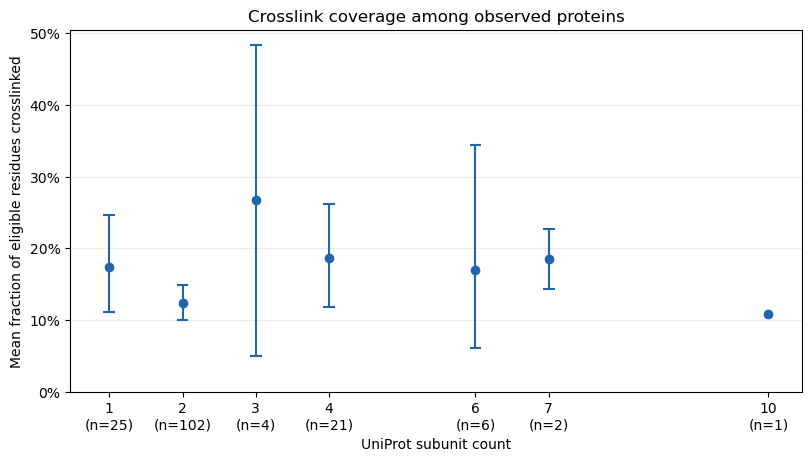

In [4]:
from matplotlib.ticker import PercentFormatter

def plot_coverage(summary, title, filename):
    fig, ax = plt.subplots(figsize=(8, 4.5), layout='constrained')
    ax.scatter(summary.subunits, summary['mean'], color='#2166ac', zorder=3)
    for row in summary.itertuples(index=False):
        if np.isfinite(row.ci_low):
            ax.vlines(row.subunits, row.ci_low, row.ci_high, color='#2166ac')
            ax.hlines([row.ci_low, row.ci_high], row.subunits - .08, row.subunits + .08, color='#2166ac')
    ax.set_xticks(summary.subunits, [f'{r.subunits}\n(n={r.proteins})' for r in summary.itertuples()])
    ax.set(xlabel='UniProt subunit count', ylabel='Mean fraction of eligible residues crosslinked',
           title=title, ylim=(0, None))
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.grid(axis='y', alpha=.25)
    fig.savefig(root / 'src/analysis' / filename, dpi=180)
    plt.show()

plot_coverage(summary, 'Crosslink coverage among observed proteins', 'subunit_xl_coverage.png')

## XL protein histogram and linear-search baseline

The histogram counts each cached, sequence-matched UniProt accession once if it appears on either side of any accepted catalog XL. It does not require successful residue localization or a known linker. Ambiguous XL protein assignments can contribute candidate accessions; unknown subunit counts are displayed separately.

The linear baseline uses rank-1 non-decoy xiSEARCH matches with evidence uniquely assigned to one accession (not protein-level FDR calls). Only checksum-matched linear outputs from cataloged search groups with a complete XL result are used, including completed groups with zero XLs. Each protein contributes once. Coverage uses the union of eligible positions across known linkers from groups where that protein was detected in the linear search; localized XL positions come from those same groups. A linear protein with no accepted XL in those groups contributes **zero**. If an accepted XL exists but its position or chemistry cannot be used to calculate coverage, the protein is reported separately rather than labeled zero. Unknown or ambiguous subunit counts are excluded from the coverage plot.

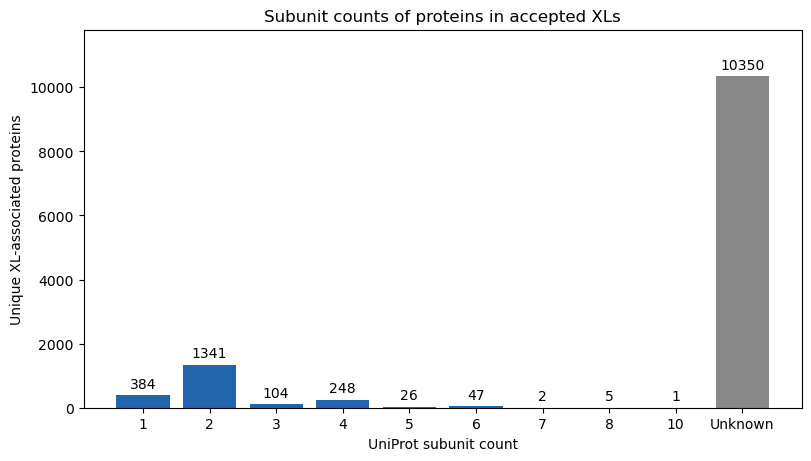

subunit_count
1            384
2           1341
3            104
4            248
5             26
6             47
7              2
8              5
10             1
Unknown    10350


In [5]:
annotated_snapshot = table.loc[table.uniprot_status.eq('matched')]
xl_proteins = annotated_snapshot.loc[annotated_snapshot.catalog_xl_associated]
known_bins = xl_proteins.subunit_count.dropna().astype(int).value_counts().sort_index()
histogram = pd.Series(known_bins.to_numpy(), index=known_bins.index.astype(str), dtype=int)
histogram.loc['Unknown'] = int(xl_proteins.subunit_count.isna().sum())
fig, ax = plt.subplots(figsize=(8, 4.5), layout='constrained')
bars = ax.bar(histogram.index, histogram.values, color=['#2166ac'] * len(known_bins) + ['#888888'])
ax.bar_label(bars, padding=3)
ax.margins(y=.14)
ax.set(xlabel='UniProt subunit count', ylabel='Unique XL-associated proteins',
       title='Subunit counts of proteins in accepted XLs')
fig.savefig(root / 'src/analysis/subunit_xl_histogram.png', dpi=180)
plt.show()
print(histogram.to_string())

19,676 linear-search proteins; 3,189 with a subunit count
linear_xl_status
linear_only            2054
xl_not_quantifiable    1016
xl_localized            119
 subunits  proteins     mean   ci_low  ci_high
        1       430 0.004838 0.001811 0.008877
        2      1346 0.004876 0.003271 0.006725
        3       108 0.008453 0.000058 0.020922
        4       207 0.014220 0.006136 0.024029
        5        34 0.000000 0.000000 0.000000
        6        40 0.019821 0.001299 0.052158
        7         3 0.033333 0.000000 0.100000
        8         3 0.000000 0.000000 0.000000
       10         1 0.067568      NaN      NaN
       12         1 0.000000      NaN      NaN


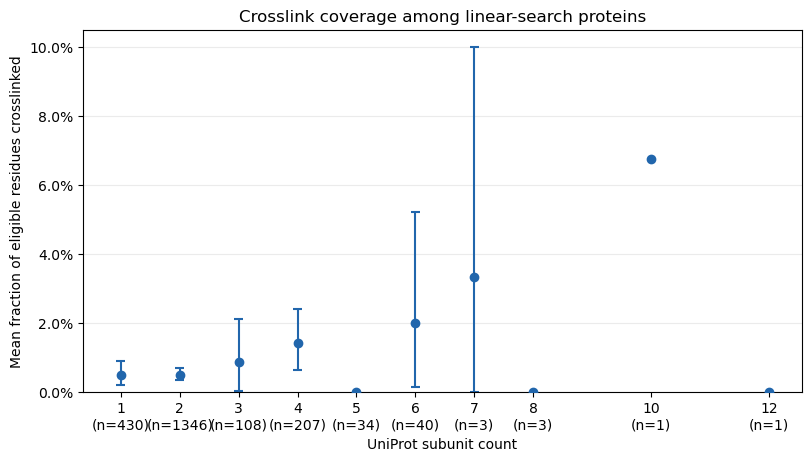

In [6]:
linear = annotated_snapshot.loc[annotated_snapshot.linear_run_count.gt(0)]
linear_annotated = linear.loc[linear.subunit_count.notna()]
linear_measured = linear_annotated.loc[linear_annotated.linear_fraction_xl.notna()]
if linear_measured.empty:
    raise ValueError('No linear-search proteins with assigned subunit counts and measurable coverage')
linear_summary = summarize_coverage(linear_measured, 'linear_fraction_xl')
print(f'{len(linear):,} linear-search proteins; {len(linear_annotated):,} with a subunit count')
print(linear_annotated.linear_xl_status.value_counts().to_string())
print(linear_summary.to_string(index=False))
plot_coverage(linear_summary, 'Crosslink coverage among linear-search proteins',
              'subunit_xl_linear_baseline.png')

## Plot 4: How often do linear-search proteins have XLs?

Both panels use all sequence-matched linear-search proteins with an assigned subunit count, including proteins whose accepted XLs could not be localized. The first panel counts any accepted catalog XL in the same search groups as the linear evidence and shows Wilson 95% confidence intervals. The stack counts deduplicated, localized protein/residue pairs in the same search groups, regardless of linker eligibility. This makes the stacked thresholds conservative: zero localized pairs does not necessarily mean zero accepted XLs.

Stacked bands are disjoint, with the highest counts at the bottom. The upper edge of each band is the fraction with at least its lower threshold; the upper edge of the zero band is always 100%. The thresholds are 0, 1, 2, 5, 10, 15, and 20, dropping thresholds above the maximum and adding that maximum if it is below 20 and not already a threshold.

Maximum localized unique XLs per protein: 36; thresholds: [0, 1, 2, 5, 10, 15, 20]
                  n  any accepted XL  >=0 localized XLs  >=1 localized XLs  >=2 localized XLs  >=5 localized XLs  >=10 localized XLs  >=15 localized XLs  >=20 localized XLs
subunit_count                                                                                                                                                               
1.0             600         0.310000                1.0           0.033333           0.016667           0.010000            0.003333            0.001667            0.001667
2.0            1988         0.361670                1.0           0.042254           0.017103           0.007042            0.002012            0.000503            0.000000
3.0             160         0.350000                1.0           0.025000           0.012500           0.006250            0.006250            0.006250            0.000000
4.0             329         0.416413                

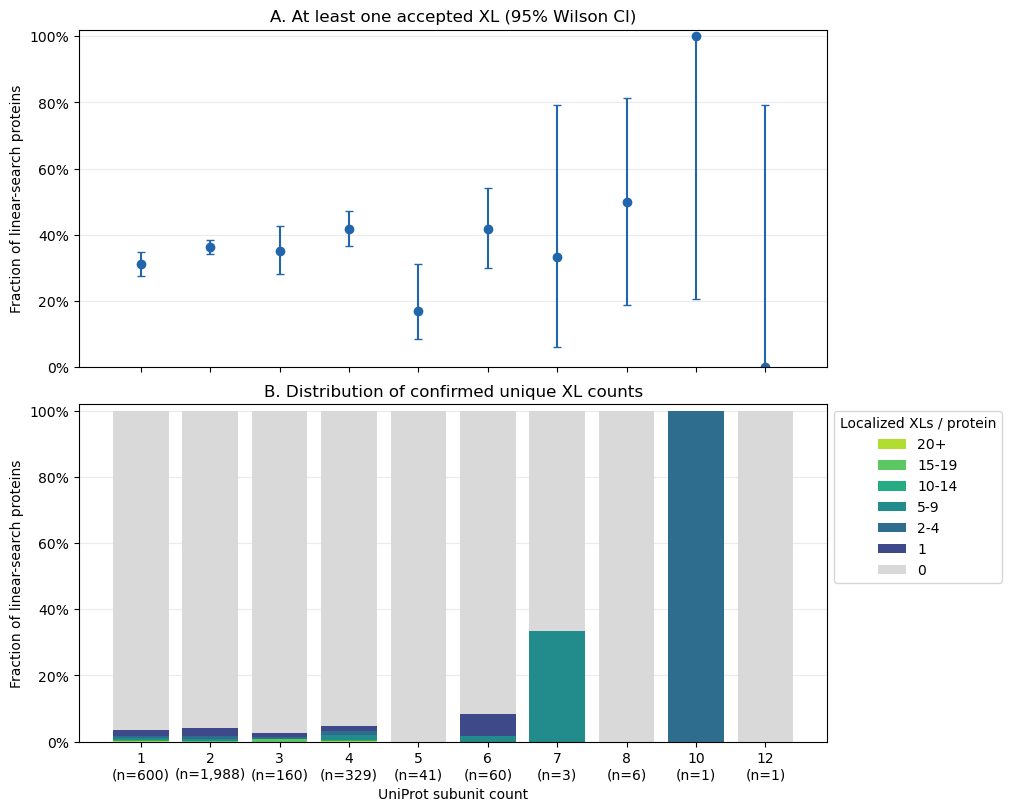

In [7]:
frequency = linear_annotated.assign(any_xl=linear_annotated.linear_xl_status.ne('linear_only'))
groups = frequency.groupby('subunit_count')
totals = groups.any_xl.agg(['size', 'sum', 'mean'])
subunits = totals.index.to_numpy(dtype=int)
n = totals['size'].to_numpy()
p = totals['mean'].to_numpy()
z = 1.959963984540054
scale = 1 + z**2 / n
center = (p + z**2 / (2 * n)) / scale
radius = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / scale
ci_low = np.clip(center - radius, 0, 1)
ci_high = np.clip(center + radius, 0, 1)

max_xl = int(frequency.linear_unique_xl_count.max())
thresholds = xl_count_thresholds(max_xl)
bands = pd.DataFrame([xl_count_bands(g.linear_unique_xl_count, thresholds) for _, g in groups],
                      index=totals.index, columns=thresholds)
fractions = bands.div(totals['size'], axis=0)
cumulative = fractions.iloc[:, ::-1].cumsum(axis=1).loc[:, thresholds]
assert np.allclose(fractions.sum(axis=1), 1)
print(f'Maximum localized unique XLs per protein: {max_xl}; thresholds: {thresholds}')
print(pd.concat([totals[['size', 'mean']].rename(columns={'size': 'n', 'mean': 'any accepted XL'}),
                 cumulative.rename(columns=lambda t: f'>={t} localized XLs')], axis=1).to_string())

x = np.arange(len(subunits))
fig, (ax_any, ax_stack) = plt.subplots(2, 1, figsize=(10, 8), sharex=True, layout='constrained')
ax_any.errorbar(x, p, yerr=np.maximum(0, [p - ci_low, ci_high - p]), fmt='o',
                color='#2166ac', capsize=3)
ax_any.set(title='A. At least one accepted XL (95% Wilson CI)', ylabel='Fraction of linear-search proteins',
           ylim=(0, 1.02))
bottom = np.zeros(len(x))
colors = plt.cm.viridis(np.linspace(.22, .88, max(1, len(thresholds) - 1)))
for i in reversed(range(len(thresholds))):
    lo = thresholds[i]
    hi = thresholds[i + 1] - 1 if i + 1 < len(thresholds) else None
    label = f'{lo}+' if hi is None and lo else str(lo) if hi in (lo, None) else f'{lo}-{hi}'
    heights = fractions[lo].to_numpy()
    ax_stack.bar(x, heights, bottom=bottom, color='#d9d9d9' if lo == 0 else colors[i - 1], label=label)
    bottom += heights
ax_stack.set(title='B. Distribution of confirmed unique XL counts', ylabel='Fraction of linear-search proteins',
             xlabel='UniProt subunit count', ylim=(0, 1.02))
ax_stack.set_xticks(x, [f'{s}\n(n={size:,})' for s, size in zip(subunits, n, strict=True)])
ax_stack.legend(title='Localized XLs / protein', bbox_to_anchor=(1, 1), loc='upper left')
for ax in (ax_any, ax_stack):
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.grid(axis='y', alpha=.25)
    ax.set_axisbelow(True)
fig.savefig(root / 'src/analysis/subunit_xl_linear_frequency.png', dpi=180)
plt.show()